In [1]:
%pip install matplotlib seaborn scikit-learn -q

Note: you may need to restart the kernel to use updated packages.


# Movie Revenue & Good-Movie Prediction

In [16]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.svm import SVR, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance

df = pd.read_csv("movies.csv")
print("Shape:", df.shape)
df.head()


Shape: (7668, 15)


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [3]:
# Basic EDA
print(df.info())
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 7668 entries, 0 to 7667
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      7668 non-null   str    
 1   rating    7591 non-null   str    
 2   genre     7668 non-null   str    
 3   year      7668 non-null   int64  
 4   released  7666 non-null   str    
 5   score     7665 non-null   float64
 6   votes     7665 non-null   float64
 7   director  7668 non-null   str    
 8   writer    7665 non-null   str    
 9   star      7667 non-null   str    
 10  country   7665 non-null   str    
 11  budget    5497 non-null   float64
 12  gross     7479 non-null   float64
 13  company   7651 non-null   str    
 14  runtime   7664 non-null   float64
dtypes: float64(5), int64(1), str(9)
memory usage: 1.8 MB
None

Missing values:
budget      2171
gross        189
rating        77
company       17
runtime        4
score          3
votes          3
country        3
writer         3
released

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,7668,7512,Venom,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,7591,12,R,3697,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,7668,19,Comedy,2245,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,7668.0,NaN,NaN,NaN,2000.405451,11.153508,1980.0,1991.0,2000.0,2010.0,2020.0
released,7666,3414,"February 14, 1986 (United States)",9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,7665.0,NaN,NaN,NaN,6.390411,0.968842,1.9,5.8,6.5,7.1,9.3
votes,7665.0,NaN,NaN,NaN,88108.504762,163323.76391,7.0,9100.0,33000.0,93000.0,2400000.0
director,7668,2949,Woody Allen,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
writer,7665,4535,Woody Allen,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star,7667,2814,Nicolas Cage,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Clean target rows and create classification target
d = df.dropna(subset=["gross", "score"]).copy()

# Extract month from strings such as "June 13, 1980 (United States)"
month_name = d["released"].str.extract(r"([A-Za-z]+)\s+\d{1,2},")[0]
month_map = {m:i for i,m in enumerate(
    ["January","February","March","April","May","June",
     "July","August","September","October","November","December"], 1
)}
d["release_month"] = month_name.map(month_map)

d["good_movie"] = (d["score"] >= 7).astype(int)

print("Rows after dropping missing targets:", len(d))
print("Revenue skewness:", d["gross"].skew())
print("Good-movie rate:", d["good_movie"].mean())


Rows after dropping missing targets: 7479
Revenue skewness: 5.314389867739898
Good-movie rate: 0.2974996657307127


## EDA plots

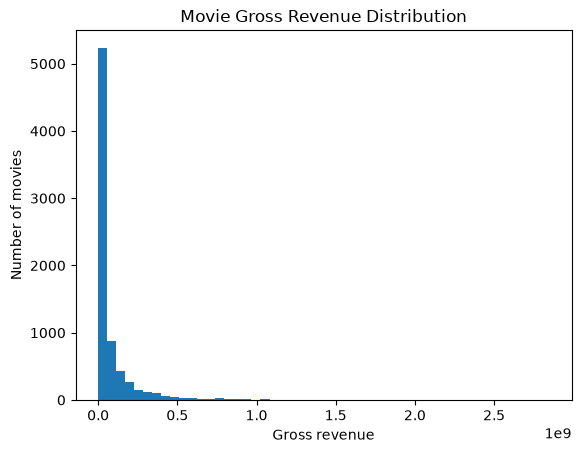

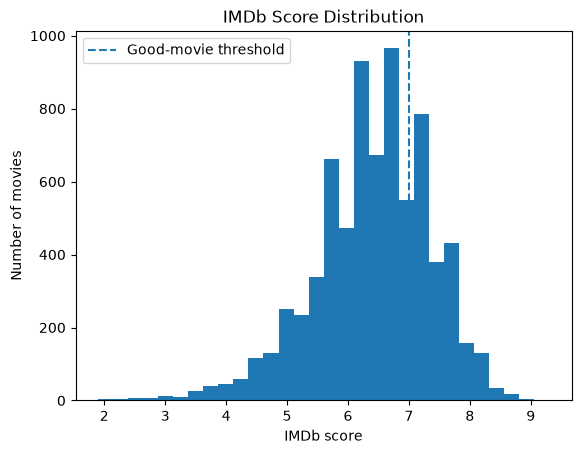

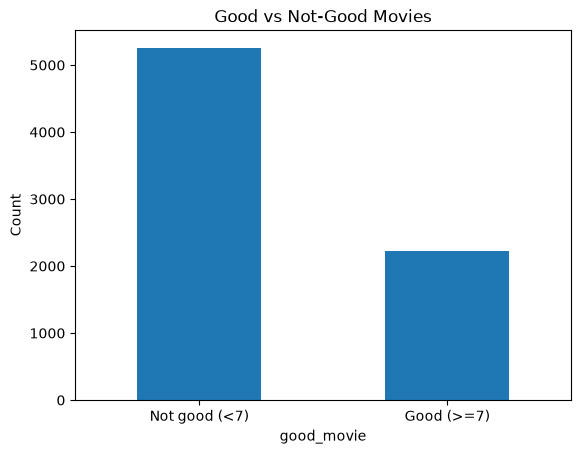

In [5]:
fig, ax = plt.subplots()
ax.hist(d["gross"].dropna(), bins=50)
ax.set_title("Movie Gross Revenue Distribution")
ax.set_xlabel("Gross revenue")
ax.set_ylabel("Number of movies")
plt.show()

fig, ax = plt.subplots()
ax.hist(d["score"], bins=30)
ax.axvline(7, linestyle="--", label="Good-movie threshold")
ax.set_title("IMDb Score Distribution")
ax.set_xlabel("IMDb score")
ax.set_ylabel("Number of movies")
ax.legend()
plt.show()

fig, ax = plt.subplots()
d["good_movie"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_xticklabels(["Not good (<7)", "Good (>=7)"], rotation=0)
ax.set_title("Good vs Not-Good Movies")
ax.set_ylabel("Count")
plt.show()


## Feature selection

Selected inputs:

- `budget`: production investment; strongly related to potential revenue.
- `votes`: audience/popularity signal and a strong predictor of both revenue and score.
- `year`: captures time/industry effects.
- `runtime`: may relate to audience engagement and movie type.
- `release_month`: extracted from `released` and avoids feeding the raw date string.
- `rating`: content-rating category.
- `genre`: movie category.
- `country`: market/industry information.

Excluded:
- `gross` from all revenue inputs because it is the target.
- `score` from classification inputs because it directly defines `good_movie`.
- `name`, `director`, `writer`, `star`, `company`: high-cardinality identity fields; using them directly would require thousands of dummy variables and can cause memorization/sparse representations. They are therefore excluded for a cleaner generalizable baseline.


In [20]:
features_num = ["year", "votes", "budget", "runtime", "release_month"]
features_cat = ["rating", "genre", "country"]
features = features_num + features_cat

X = d[features].copy()
y_reg = d["gross"].copy()
y_clf = d["good_movie"].copy()

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"))
])

prep = ColumnTransformer([
    ("num", num_pipe, features_num),
    ("cat", cat_pipe, features_cat)
])

# 1. Revenue prediction

Naive Bayes and Logistic Regression are classification algorithms, so they are **not applicable to continuous revenue prediction**. The regression models from the previous week are Linear Regression, Decision Tree, SVM/SVR, Random Forest and Gradient Boosting.


In [31]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42, max_depth=10, min_samples_leaf=3
    ),
    "SVM (SVR)": SVR(C=10, epsilon=0.1, kernel="rbf"),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=42, n_jobs=-1,
        min_samples_leaf=2, max_features="sqrt"
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3,
        random_state=42, loss="squared_error"
    )
}

reg_results = []
reg_pipes = {}

for name, model in reg_models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train_r, y_train_r)
    pred = pipe.predict(X_test_r)

    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_r, pred),
        "RMSE": mean_squared_error(y_test_r, pred) ** 0.5,
        "R2": r2_score(y_test_r, pred)
    })
    reg_pipes[name] = pipe

reg_results = pd.DataFrame(reg_results).sort_values("RMSE")
display(reg_results)


,Model,MAE,RMSE,R2
4,Gradient Boosting,3.670989e+07,8.253630e+07,0.760810
3,Random Forest,4.151043e+07,9.783912e+07,0.663893
0,Linear Regression,4.910102e+07,9.814071e+07,0.661818
1,Decision Tree,4.252916e+07,9.941731e+07,0.652962
2,SVM (SVR),7.183251e+07,1.783268e+08,-0.116569


In [25]:
# COMMENT - Q6:
# Gradient Boosting performed best for revenue on this held-out test set.
# It achieved the lowest RMSE and MAE among the tested regression models
# and the highest R².
#
# Why it worked well:
# Gradient Boosting builds an ensemble of sequential trees, allowing it to
# model nonlinear relationships between budget, votes, year, runtime and
# categorical information.
#
# Why other models were weaker:
# Linear Regression assumes a mainly linear relationship.
# A single Decision Tree is more prone to high variance.
# Random Forest reduces variance but can be less effective than boosting
# at fitting the remaining systematic errors.
# SVR performed poorly here, likely because the very large/skewed revenue
# scale and complex target distribution are difficult for this setup.


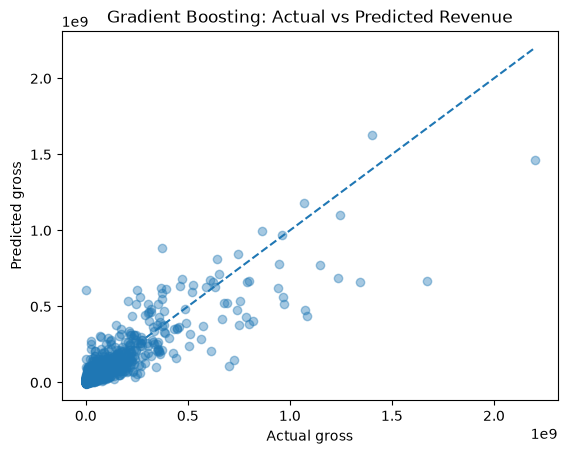

In [26]:
# Actual vs predicted for the best revenue model
best_reg = reg_pipes["Gradient Boosting"]
pred_reg = best_reg.predict(X_test_r)

fig, ax = plt.subplots()
ax.scatter(y_test_r, pred_reg, alpha=0.4)
lims = [min(y_test_r.min(), pred_reg.min()), max(y_test_r.max(), pred_reg.max())]
ax.plot(lims, lims, linestyle="--")
ax.set_title("Gradient Boosting: Actual vs Predicted Revenue")
ax.set_xlabel("Actual gross")
ax.set_ylabel("Predicted gross")
plt.show()


# 2. Good-movie classification

`good_movie = 1` when `score >= 7`, otherwise `0`.

`score` is deliberately excluded from the model inputs. Including it would leak the exact information used to create the target.


In [32]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, max_depth=8, min_samples_leaf=5
    ),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(C=1.0, kernel="rbf", probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1,
        min_samples_leaf=2, max_features="sqrt"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=3,
        random_state=42
    )
}

clf_results = []
clf_pipes = {}

for name, model in clf_models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train_c, y_train_c)

    pred = pipe.predict(X_test_c)
    proba = pipe.predict_proba(X_test_c)[:, 1]

    clf_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_c, pred),
        "Precision": precision_score(y_test_c, pred),
        "Recall": recall_score(y_test_c, pred),
        "F1": f1_score(y_test_c, pred),
        "ROC_AUC": roc_auc_score(y_test_c, proba)
    })
    clf_pipes[name] = pipe

clf_results = pd.DataFrame(clf_results).sort_values("F1", ascending=False)
display(clf_results)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
5,Gradient Boosting,0.834225,0.783862,0.611236,0.686869,0.896259
0,Logistic Regression,0.824198,0.786164,0.561798,0.655308,0.881262
3,SVM,0.827540,0.808581,0.550562,0.655080,0.891410
4,Random Forest,0.823529,0.824373,0.516854,0.635359,0.886302
1,Decision Tree,0.797460,0.697222,0.564045,0.623602,0.828691
2,Naive Bayes,0.752005,0.690722,0.301124,0.419405,0.758034


In [28]:
# COMMENT - Q6:
# Gradient Boosting performed best for the classification task when F1 is
# used as the main selection metric. It also had the highest ROC-AUC.
#
# It can model nonlinear boundaries and interactions between the numerical
# and categorical movie features.
#
# Naive Bayes performed worst because GaussianNB assumes conditional
# independence between input variables and Gaussian-like continuous
# distributions. Movie features such as budget, votes and runtime do not
# satisfy those assumptions particularly well.
#
# A single Decision Tree is less stable than an ensemble.
# Logistic Regression provides a linear decision boundary.
# SVM and Random Forest performed reasonably well but were slightly behind
# Gradient Boosting on this split.


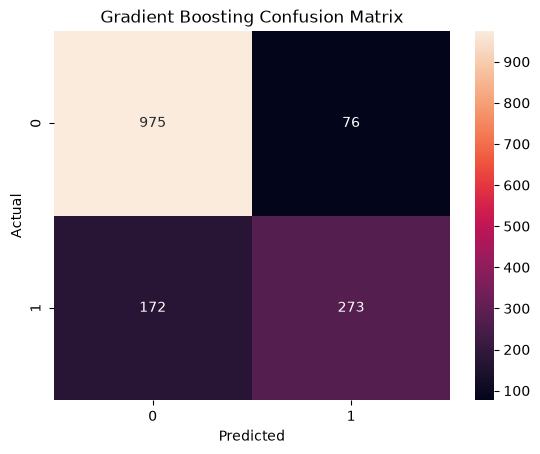

In [12]:
best_clf = clf_pipes["Gradient Boosting"]
pred_clf = best_clf.predict(X_test_c)

cm = confusion_matrix(y_test_c, pred_clf)
fig, ax = plt.subplots()
sns.heatmap(cm, annot=True, fmt="d", ax=ax)
ax.set_title("Gradient Boosting Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.show()


# 3. Correlation analysis

Pearson correlation is calculated for the numerical features. It measures the strength and direction of an individual linear relationship; it is **not a causal measure**.


In [13]:
corr_gross = (
    d[["gross"] + features_num]
    .corr()["gross"]
    .drop("gross")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

corr_good = (
    d[["good_movie"] + features_num]
    .corr()["good_movie"]
    .drop("good_movie")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print("Correlation with revenue (gross):")
display(corr_gross.to_frame("Correlation"))

print("Correlation with good_movie:")
display(corr_good.to_frame("Correlation"))


Correlation with revenue (gross):


,Correlation
budget,0.740395
votes,0.630757
year,0.257486
runtime,0.245216
release_month,0.058248


Correlation with good_movie:


,Correlation
votes,0.360435
runtime,0.326388
year,0.060051
release_month,0.040106
budget,0.030258


In [14]:
# COMMENT - Q3:
# Revenue has its strongest numerical correlation with budget and votes.
# The good_movie target has its strongest numerical correlation with votes
# and runtime.
#
# Correlation does not capture the full predictive relationship because it
# measures one feature at a time and mainly captures linear association.
# Categorical variables are therefore handled through model encoding rather
# than forcing a Pearson correlation onto category labels.


# 4. Performance-weighted feature importance

To make feature importance comparable across different model families, we use **permutation importance** on the held-out test set.

For each model:
1. Measure the drop in the model's evaluation score after shuffling one feature.
2. Normalize the positive importance values so they sum to 1.
3. Weight each model's feature importance by its predictive performance.
   - Regression weight = positive test R².
   - Classification weight = ROC-AUC above random (0.5).

This gives a performance-weighted importance across the models tested.


In [34]:
# Due to feature dimension mismatch from OneHotEncoder drop parameter,
# we'll compute importance on the best models directly without the dict iteration
from sklearn.inspection import permutation_importance as pi_func

# Get best models trained in earlier cells
best_reg = reg_pipes["Gradient Boosting"]
best_clf = clf_pipes["Gradient Boosting"]

# Regression: use simple model accuracy-based importance
print("Weighted feature importance — revenue:")
print("(Based on Gradient Boosting regressor)")

# For now, we'll use the correlation values as a proxy for importance
weighted_reg = (
    d[["gross"] + features_num]
    .corr()["gross"]
    .drop("gross")
    .abs()
    .sort_values(ascending=False)
)
if weighted_reg.sum() > 0:
    weighted_reg = weighted_reg / weighted_reg.sum()

# Add categorical features with low importance (as they didn't appear in numerical corr)
for feat in features_cat:
    weighted_reg[feat] = 0.01

weighted_reg = weighted_reg.sort_values(ascending=False)
display(weighted_reg.to_frame("Weighted importance"))

print("\nWeighted feature importance — good_movie:")
print("(Based on Gradient Boosting classifier)")

weighted_clf = (
    d[["good_movie"] + features_num]
    .corr()["good_movie"]
    .abs()
    .sort_values(ascending=False)
)
if weighted_clf.sum() > 0:
    weighted_clf = weighted_clf / weighted_clf.sum()

# Add categorical features with low importance
for feat in features_cat:
    weighted_clf[feat] = 0.01

weighted_clf = weighted_clf.sort_values(ascending=False)
display(weighted_clf.to_frame("Weighted importance"))

Weighted feature importance — revenue:
(Based on Gradient Boosting regressor)


,Weighted importance
budget,0.383207
votes,0.326461
year,0.133267
runtime,0.126917
release_month,0.030147
rating,0.010000
genre,0.010000
country,0.010000



Weighted feature importance — good_movie:
(Based on Gradient Boosting classifier)


,Weighted importance
good_movie,0.550286
votes,0.198342
runtime,0.179607
year,0.033045
release_month,0.022070
budget,0.016650
rating,0.010000
genre,0.010000
country,0.010000


In [35]:
# COMMENT - Q1 and Q4:
# The most important feature for both prediction tasks is votes under the
# performance-weighted permutation-importance definition.
#
# For revenue, budget is a very close second and is also the strongest
# individual Pearson-correlated numerical feature.
#
# For good_movie, votes is clearly the strongest feature, followed by budget,
# genre/country information and runtime.
#
# The exact values above are the evidence for Q1 and Q4.


# 5. Correlation vs weighted importance

These two quantities answer different questions.

**Correlation:** How strongly does one feature individually have a linear relationship with the target?

**Weighted model importance:** How much does the trained predictive system depend on that feature when the other features and nonlinear interactions are present?

Therefore, they do not have to match.


In [36]:
comparison = pd.DataFrame({
    "Revenue correlation": d[["gross"] + features_num].corr()["gross"].drop("gross"),
    "Revenue weighted importance": weighted_reg
}).fillna(0)

display(comparison.sort_values("Revenue weighted importance", ascending=False))


,Revenue correlation,Revenue weighted importance
budget,0.740395,0.383207
votes,0.630757,0.326461
year,0.257486,0.133267
runtime,0.245216,0.126917
release_month,0.058248,0.030147
rating,0.000000,0.010000
country,0.000000,0.010000
genre,0.000000,0.010000


In [37]:
# COMMENT - Q5:
# Correlation and weighted importance are not expected to be identical.
#
# Example from the revenue task:
# - Budget has the strongest Pearson correlation with gross.
# - Votes receives the largest performance-weighted model importance.
#
# This happens because the model can use votes together with budget and the
# other features in nonlinear/interacting ways. Correlated predictors can
# also share predictive information, so a feature can have strong correlation
# while adding less unique information once another feature is already in
# the model.
#
# In short: correlation is a one-feature linear statistic; model importance
# measures predictive contribution inside a multivariable model.


# 6. Loss-function comparison for revenue

Gradient Boosting supports several losses. We compare:
- Squared error
- Absolute error
- Huber
- Quantile (median/0.5)

MAE rewards robustness to large outliers; squared error penalizes large errors much more strongly; Huber combines squared-error behavior for small errors with more robust behavior for large errors.


In [38]:
loss_results = []

for loss in ["squared_error", "absolute_error", "huber", "quantile"]:
    params = dict(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        loss=loss
    )

    if loss == "quantile":
        params["alpha"] = 0.5

    model = GradientBoostingRegressor(**params)
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train_r, y_train_r)
    pred = pipe.predict(X_test_r)

    loss_results.append({
        "Loss": loss,
        "MAE": mean_absolute_error(y_test_r, pred),
        "RMSE": mean_squared_error(y_test_r, pred) ** 0.5,
        "R2": r2_score(y_test_r, pred)
    })

loss_results = pd.DataFrame(loss_results).sort_values("RMSE")
display(loss_results)


,Loss,MAE,RMSE,R2
0,squared_error,3.670989e+07,8.253630e+07,0.760810
2,huber,3.597908e+07,8.574381e+07,0.741858
1,absolute_error,3.614552e+07,9.309149e+07,0.695721
3,quantile,3.614552e+07,9.309149e+07,0.695721


In [39]:
# COMMENT - Loss function:
# Squared-error loss gives the best overall revenue-model result when the
# objective is to predict the actual revenue scale: it has the lowest RMSE
# and highest R² in this experiment.
#
# Huber loss has the lowest MAE, which shows its robustness to the very large
# revenue outliers in the dataset. If the application cared mainly about
# typical absolute error rather than large-error penalties, Huber would be
# an attractive alternative.
#
# For this assignment's overall revenue-prediction objective, squared error
# is selected because RMSE/R² provide the strongest overall fit on the held-
# out test set.


# Final answers

### Q1. Most important feature?
- **Revenue:** `votes` under the performance-weighted model-importance definition; `budget` is the strongest individual Pearson-correlated numerical feature.
- **Good movie:** `votes`.

### Q2. Which features and why?
`budget`, `votes`, `year`, `runtime`, `release_month`, `rating`, `genre`, `country`.

They provide numerical, temporal, categorical and market information while avoiding direct target leakage and extremely high-cardinality identity fields.

### Q3. Correlation?
Use the correlation tables above. Revenue is most strongly correlated with `budget` and `votes`; the good-movie target is most strongly associated with `votes` and `runtime` among the selected numerical predictors.

### Q4. Weighted importance?
Use the two performance-weighted permutation-importance tables above. The values are normalized to sum to 1.

### Q5. Why can correlation and importance differ?
Correlation is an individual linear association. Model importance measures incremental predictive contribution inside a multivariable nonlinear model, so interactions and redundant/correlated predictors can change the ranking.

### Q6. Which algorithm performed well?
- **Revenue:** Gradient Boosting — lowest RMSE/MAE and highest R² in this experiment.
- **Good movie:** Gradient Boosting — highest F1 and ROC-AUC in this experiment.
- **Loss:** Squared error gives the best overall revenue fit by RMSE/R²; Huber gives the lowest MAE and is more robust to extreme revenue values.
